In [240]:
RANDOM_STATE = 42

### 0. Предобработка

#### 0.1 датасет 1

In [3]:
!unzip -o data.zip -d data

Archive:  data.zip
  inflating: data/labeled.csv        


In [392]:
import pandas as pd
import numpy as np
import re
!pip install pymorphy2
import pymorphy2


df = pd.read_csv('data/labeled.csv')
df = df.drop_duplicates()

def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'www\S+', '', text)
    text = re.sub(r"\'s", " ", text)
    text = re.sub('\W', ' ', text)
    text = re.sub('\s+', ' ', text)
    text = text.strip(' ')
    return text

df['comment'] = df['comment'].apply(clean_text)

is_en = lambda x: len(re.findall('[a-z]', x)) / max(len(x.replace(' ', '')), 1)
df = df[df['comment'].apply(is_en) < 0.2]

df = df[df['comment'] != '']
df = df[(df['comment'].apply(lambda x: len(x)) < 300)]

import nltk
nltk.download('stopwords')


morph = pymorphy2.MorphAnalyzer()
ru_stopwords = stopwords.words("russian") + ['это', 'её']
df['comment'] = df['comment'].map(lambda comment: " ".join(filter(lambda word: word not in ru_stopwords, map(lambda word: morph.parse(word)[0].normal_form, word_tokenize(comment)))))
print(df.shape)
df.head()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,comment,toxic
0,верблюд дебил бл,1.0
1,хохол отдушина затюканый россиянин мол вон хох...,1.0
2,собака собачий смерть,1.0
3,страница обновить дебил оскорбление доказать ф...,1.0
4,убедить 6 страничный пдф скрипаль отравить рос...,1.0


In [141]:
df = df[df['comment'].notnull()]
df.to_csv('1.csv', index=False)

#### 0.2 датасет 2

In [271]:
df = pd.read_csv('data_tokenized.csv', sep=';', index_col=0)
df['comment'] = df['comment_lemmatized'].apply(eval).apply(lambda x: " ".join(x))

labels_dict = dict(map(lambda x: (x[1], x[0]), list(enumerate(df['labels_str'].value_counts().index.tolist()))))
print(labels_dict)
df['toxic'] = df['labels_str'].map(lambda x: labels_dict[x])
df = df[['comment', 'toxic']]
print(df.shape)
df.head(10)

{'NORMAL': 0, 'INSULT_THREAT': 1, 'THREAT': 2, 'OBSCENITY': 3, 'INSULT': 4, 'INSULT_OBSCENITY': 5, 'INSULT_OBSCENITY_THREAT': 6, 'OBSCENITY_THREAT': 7}
(13972, 2)


,comment,toxic
1,сегодня проезжать рабочий дом снитенко гомолыс...,0
2,очередной лохотрон придумывать очередной налог...,0
3,ретро дежавю сложно понять чужое сердце лиш ощ...,0
4,статус агрогородок получить,0
5,август поздно вечером наслать такой потеряшка ...,0
6,вчера надыбал новый стикер,0
8,стоянка никто проверять безопасность ребёнок в...,0
9,красота показать почемунуть,0
10,ходунок цена,0
11,любовьс первый взгляд,0


In [272]:
df = df[df['comment'].notnull()]
df.to_csv('2.csv', index=False)

#### 0.3 датасет 3

In [483]:
df = pd.read_csv('train.tsv', sep='\t')
df_t = pd.DataFrame(map(lambda x: (x, 1), df['toxic_comment'].values), columns=['comment', 'toxic'])
df_nt = pd.DataFrame(map(lambda x: (x, 0), df['neutral_comment1'].values), columns=['comment', 'toxic'])
df = pd.concat([df_t, df_nt])


def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'www\S+', '', text)
    text = re.sub(r"\'s", " ", text)
    text = re.sub('\W', ' ', text)
    text = re.sub('\s+', ' ', text)
    text = text.strip(' ')
    return text

df['comment'] = df['comment'].apply(clean_text)

is_en = lambda x: len(re.findall('[a-z]', x)) / max(len(x.replace(' ', '')), 1)
df = df[df['comment'].apply(is_en) < 0.2]

import nltk
nltk.download('stopwords')


morph = pymorphy2.MorphAnalyzer()
ru_stopwords = stopwords.words("russian") + ['это', 'её']
df['comment'] = df['comment'].map(lambda comment: " ".join(filter(lambda word: word not in ru_stopwords, map(lambda word: morph.parse(word)[0].normal_form, word_tokenize(comment)))))
df = df[df['comment'] != '']
df = df[(df['comment'].apply(lambda x: len(x)) < 300)]
df = df[(df['comment'].apply(lambda x: len(x)) > 2)]
print(df.shape)
df.head()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


(13825, 2)


,comment,toxic
0,блядь хёра свой доказательство,1
1,деанон петух,1
2,хернуть всякий писать лайк долбоебизм,1
3,пидор страдать,1
4,гондон путинский артист,1


In [484]:
df = df[df['comment'] != '4']
df = df[df['comment'].notnull()]
print(df.shape)
df.to_csv('3.csv', index=False)

(13825, 2)


### Загрузка датасета

In [273]:
!unzip -o data.zip -d data

Archive:  data.zip
  inflating: data/labeled.csv        


#### 1. датасет 1

In [322]:
df = pd.read_csv('data/1.csv')
print(df.shape)
df.head(10)

(12420, 2)


,comment,toxic
0,верблюд дебил бл,1.0
1,хохол отдушина затюканый россиянин мол вон хох...,1.0
2,собака собачий смерть,1.0
3,страница обновить дебил оскорбление доказать ф...,1.0
4,убедить 6 страничный пдф скрипаль отравить рос...,1.0
5,стан являться эталон современный система здрав...,1.0
6,шапка ссылка инф текущий фильм марвести ссылка...,0.0
7,упад строить технология разворовать трещина по...,1.0
8,ебать разносить шизик,1.0
9,обосраться сидеть обтекать,1.0


In [323]:
LABELS_COUNT = 2

#### 2. датасет 2


In [333]:
df = pd.read_csv('data/2.csv')
print(df.shape)
df.head(10)

(13972, 2)


,comment,toxic
0,сегодня проезжать рабочий дом снитенко гомолыс...,0
1,очередной лохотрон придумывать очередной налог...,0
2,ретро дежавю сложно понять чужое сердце лиш ощ...,0
3,статус агрогородок получить,0
4,август поздно вечером наслать такой потеряшка ...,0
5,вчера надыбал новый стикер,0
6,стоянка никто проверять безопасность ребёнок в...,0
7,красота показать почемунуть,0
8,ходунок цена,0
9,любовьс первый взгляд,0


In [332]:
LABELS_COUNT = 8

#### 3. датасет 3

In [485]:
df = pd.read_csv('data/3.csv')
print(df.shape)

(13825, 2)


In [486]:
LABELS_COUNT = 2

#### train test split

In [487]:
from sklearn.model_selection import train_test_split
df_train, df_test = train_test_split(df, test_size=0.33, random_state=RANDOM_STATE)
y_train = df_train['toxic']
y_true = df_test['toxic']

## Baseline

In [531]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns


metrics = dict()

def get_metrics(y_true, y_pred, title=None):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(3, 3))

    ax = sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap=sns.color_palette("pastel", 5))
    ax.set_xlabel("Predicted", labelpad=20)
    ax.set_ylabel("Actual", labelpad=20)
    if title:
        ax.set_title(title)
    plt.show()

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')

    print(f'accuracy:\t{accuracy}')
    print(f'precision:\t{precision}')
    print(f'recall:\t\t{recall}')
    print(f'f1:\t\t{f1}')

    if title:
        metrics[title] = dict()
        metrics[title]['accuracy'] = accuracy
        metrics[title]['precision'] = precision
        metrics[title]['recall'] = recall
        metrics[title]['f1'] = f1

### 1. Модель с константным предсказанием

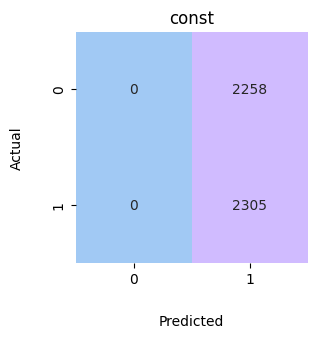

accuracy:	0.505150120534736
precision:	0.25517664427625825
recall:		0.505150120534736
f1:		0.33907135347483003


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [532]:
y_pred = np.full(y_true.shape, 1)
get_metrics(y_true, y_pred, 'const')

### 2. Модель со случайным предсказанием

In [534]:
class BaseLineModel():
    def __init__(self, predict_function):
        self.predict_function = predict_function

    def predict(self, X):
        return np.array(list(map(self.predict_function, X)))

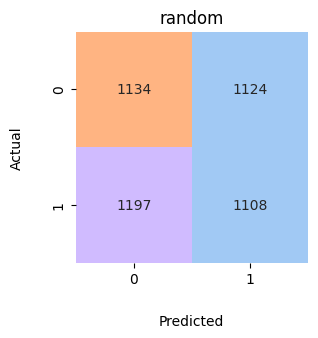

accuracy:	0.4913434144203375
precision:	0.491502265557959
recall:		0.4913434144203375
f1:		0.4912970447463165


In [535]:
def random_prediction(comment):
    return np.random.randint(0, LABELS_COUNT)


random_model = BaseLineModel(random_prediction)
y_pred = random_model.predict(df_test['comment'])
get_metrics(y_true, y_pred, 'random')

### 3. Lexicon-based

In [536]:
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk import word_tokenize
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from nltk.util import ngrams

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [537]:
toxic_dict = dict()
for i in range(1, LABELS_COUNT):
    comments = " ".join(df_train[df_train['toxic'] == i]['comment'].tolist())
    comments_tokens = word_tokenize(comments)
    text = nltk.Text(comments_tokens)
    text = [word for word in text if word not in ru_stopwords]
    f_dist = FreqDist(text)
    toxic_dict[i] = set(map(lambda x: x[0], f_dist.most_common(20)))
print(toxic_dict)

{1: {'нахуй', 'сука', 'знать', 'хуйня', 'хотеть', 'пидор', 'ещё', 'мочь', 'блядь', 'бля', 'человек', 'всё', 'весь', 'свой', 'тварь', 'делать', 'жопа', 'пиздец', 'хуй', 'просто'}}


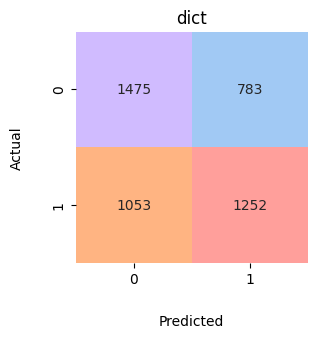

accuracy:	0.5976331360946746
precision:	0.5995129127431952
recall:		0.5976331360946746
f1:		0.5964667873896508


In [538]:
def dict_prediction(comment):
    for word in comment.split(' '):
        for label in toxic_dict:
            if word in toxic_dict[label]:
                return label
    return 0


dict_model = BaseLineModel(dict_prediction)
y_pred = dict_model.predict(df_test['comment'])
get_metrics(y_true, y_pred, 'dict')

### 4. Rule-based

In [495]:
!pip install fkscore
import fkscore

In [540]:
df_test_copy = df_test.copy()
df_test_copy['fkscore'] = df_test_copy['comment'].apply(lambda comment: fkscore.fkscore(comment).score['readability'])
print(df_test_copy[df_test_copy['toxic'] == 0]['fkscore'].describe())
print()
print(df_test_copy[df_test_copy['toxic'] != 0]['fkscore'].describe())

count    2258.000000
mean      117.182195
std         2.835184
min        96.025000
25%       116.145000
50%       118.175000
75%       119.190000
max       121.220000
Name: fkscore, dtype: float64

count    2305.000000
mean      115.888066
std         3.055605
min        88.905000
25%       114.115000
50%       116.145000
75%       118.175000
max       134.080000
Name: fkscore, dtype: float64


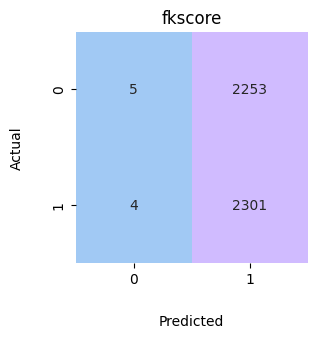

accuracy:	0.5053692746000439
precision:	0.5301538476937957
recall:		0.5053692746000439
f1:		0.341109922119548


In [541]:
def fkscore_prediction(comment):
    score = fkscore.fkscore(comment).score
    return score['readability'] > 102


fkscore_model = BaseLineModel(fkscore_prediction)
y_pred = fkscore_model.predict(df_test['comment'])
get_metrics(y_true, y_pred, 'fkscore')

### 5. BoW

#### 5.1 Logistic Regression

In [542]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer


vectorizer = CountVectorizer()
vectorizer.fit(df_train['comment'])
X_train = vectorizer.transform(df_train['comment'])
X_test = vectorizer.transform(df_test['comment'])
lr = LogisticRegression()
lr.fit(X_train, y_train)

LogisticRegression()

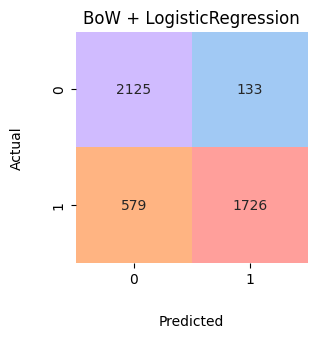

accuracy:	0.843962305500767
precision:	0.8578987917290148
recall:		0.843962305500767
f1:		0.8426183966984363


In [543]:
y_pred = lr.predict(X_test)
get_metrics(y_true, y_pred, 'BoW + LogisticRegression')

#### 5.2 SVC

In [544]:
from sklearn import svm


clf = svm.SVC()
clf.fit(X_train, y_train)

SVC()

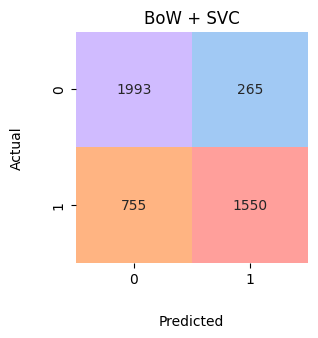

accuracy:	0.7764628533859304
precision:	0.7902876358154705
recall:		0.7764628533859304
f1:		0.7741101810385959


In [545]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'BoW + SVC')

### 6. TF-IDF

#### 6.1 LogisticRegression

In [547]:
from sklearn.feature_extraction.text import TfidfVectorizer


vectorizer = TfidfVectorizer()
vectorizer.fit(df_train['comment'])
X_train = vectorizer.transform(df_train['comment'])
X_test = vectorizer.transform(df_test['comment'])
lr = LogisticRegression()
lr.fit(X_train, y_train)

LogisticRegression()

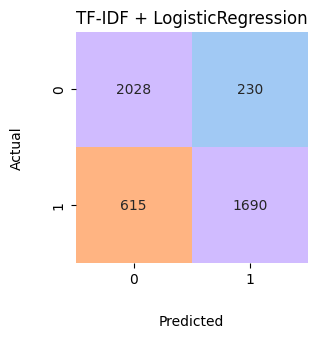

accuracy:	0.8148148148148148
precision:	0.8243405449054806
recall:		0.8148148148148148
f1:		0.8136510311576625


In [548]:
y_pred = lr.predict(X_test)
get_metrics(y_true, y_pred, 'TF-IDF + LogisticRegression')

#### 6.2 SVC

In [549]:
from sklearn import svm


clf = svm.SVC()
clf.fit(X_train, y_train)

SVC()

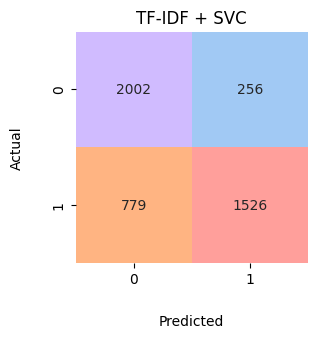

accuracy:	0.7731755424063116
precision:	0.78881582774298
recall:		0.7731755424063116
f1:		0.7704336555699756


In [551]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'TF-IDF + SVC')

#### 6.3 GradientBoosting

In [552]:
from sklearn.ensemble import GradientBoostingClassifier


clf = GradientBoostingClassifier(n_estimators=100, learning_rate=1.0, max_depth=1, random_state=RANDOM_STATE)
clf.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=1.0, max_depth=1, random_state=42)

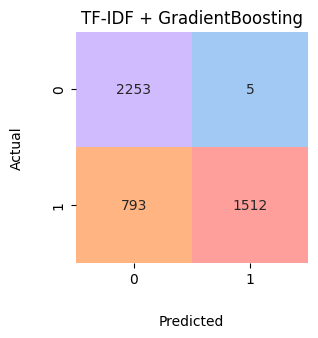

accuracy:	0.8251150558842867
precision:	0.8695051099175968
recall:		0.8251150558842867
f1:		0.8200776998201293


In [553]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'TF-IDF + GradientBoosting')

### 7. N-grams + Naive Byas

In [554]:
from sklearn.naive_bayes import MultinomialNB


vectorizer = CountVectorizer(ngram_range=(1, 2))
vectorizer.fit(df_train['comment'])
X_train = vectorizer.transform(df_train['comment'])
X_test = vectorizer.transform(df_test['comment'])
clf = MultinomialNB()
clf.fit(X_train, y_train)

MultinomialNB()

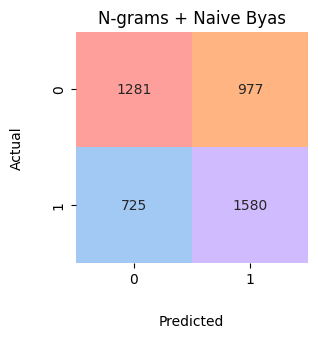

accuracy:	0.6269997808459347
precision:	0.6281414646691248
recall:		0.6269997808459347
f1:		0.6256441274523844


In [555]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'N-grams + Naive Byas')

### 8. Word2Vec

#### 8.1 LogisticRegression

In [556]:
from gensim.models import Word2Vec

VECTOR_SIZE = 100
sentences = [sentence.split() for sentence in df_train['comment']]
w2v_model = Word2Vec(sentences, vector_size=VECTOR_SIZE, window=5, min_count=5, workers=4)

In [557]:
def vectorize(comment):
    words = comment.split()
    words_vecs = [w2v_model.wv[word] for word in words if word in w2v_model.wv]
    if len(words_vecs) == 0:
        return np.zeros(VECTOR_SIZE)
    words_vecs = np.array(words_vecs)
    return words_vecs.mean(axis=0)


X_train = np.array([vectorize(comment) for comment in df_train['comment']])
X_test = np.array([vectorize(comment) for comment in df_test['comment']])
clf = LogisticRegression()
clf.fit(X_train, y_train)

LogisticRegression()

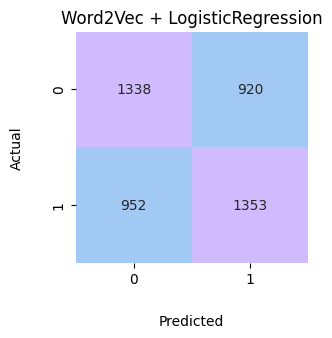

accuracy:	0.5897435897435898
precision:	0.5898205152342866
recall:		0.5897435897435898
f1:		0.5897530477666518


In [558]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'Word2Vec + LogisticRegression')

#### 8.2 KNN

In [559]:
from sklearn.neighbors import KNeighborsClassifier


clf = KNeighborsClassifier(n_neighbors=3)
clf.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

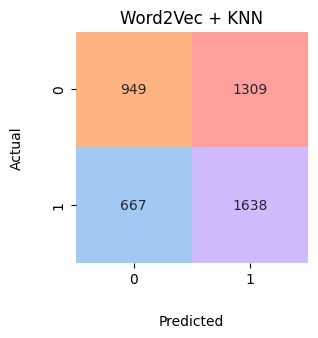

accuracy:	0.5669515669515669
precision:	0.5713740926135978
recall:		0.5669515669515669
f1:		0.5575368690781419


In [560]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'Word2Vec + KNN')

#### 8.3 SVC

In [561]:
clf = svm.SVC()
clf.fit(X_train, y_train)

SVC()

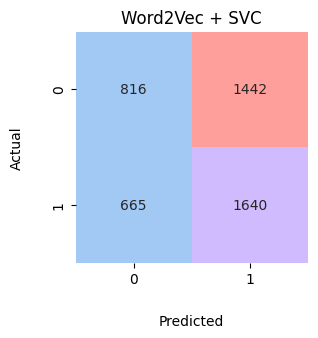

accuracy:	0.5382423843962305
precision:	0.5414534172688215
recall:		0.5382423843962305
f1:		0.5235646218791309


In [562]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'Word2Vec + SVC')

#### 8.4 GradientBoosting

In [563]:
clf = GradientBoostingClassifier(n_estimators=100, learning_rate=1.0, max_depth=1, random_state=RANDOM_STATE)
clf.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=1.0, max_depth=1, random_state=42)

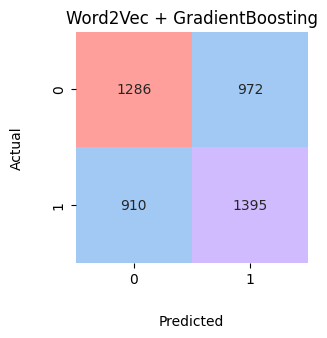

accuracy:	0.5875520490905106
precision:	0.5875011852877962
recall:		0.5875520490905106
f1:		0.5874181016896324


In [564]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'Word2Vec + GradientBoosting')

### 9. GloVe

#### 9.1 LogisticRegression

In [565]:
!pip install navec
!wget https://storage.yandexcloud.net/natasha-navec/packs/navec_hudlit_v1_12B_500K_300d_100q.tar

--2024-12-11 18:12:15--  https://storage.yandexcloud.net/natasha-navec/packs/navec_hudlit_v1_12B_500K_300d_100q.tar
Resolving storage.yandexcloud.net (storage.yandexcloud.net)... 213.180.193.243, 2a02:6b8::1d9
Connecting to storage.yandexcloud.net (storage.yandexcloud.net)|213.180.193.243|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 53012480 (51M) [application/x-tar]
Saving to: ‘navec_hudlit_v1_12B_500K_300d_100q.tar.2’

navec_hudlit_v1_12B 100%[===================>]  50.56M  16.4MB/s    in 3.6s    

2024-12-11 18:12:19 (14.1 MB/s) - ‘navec_hudlit_v1_12B_500K_300d_100q.tar.2’ saved [53012480/53012480]



In [566]:
from navec import Navec

path = 'navec_hudlit_v1_12B_500K_300d_100q.tar'
navec = Navec.load(path)

In [567]:
def vectorize(comment):
    words = comment.split()
    words_vecs = [navec[word] for word in words if word in navec]
    if len(words_vecs) == 0:
        return np.zeros(300)
    words_vecs = np.array(words_vecs)
    return words_vecs.mean(axis=0)


X_train = np.array([vectorize(comment) for comment in df_train['comment']])
X_test = np.array([vectorize(comment) for comment in df_test['comment']])
clf = LogisticRegression()
clf.fit(X_train, y_train)

LogisticRegression()

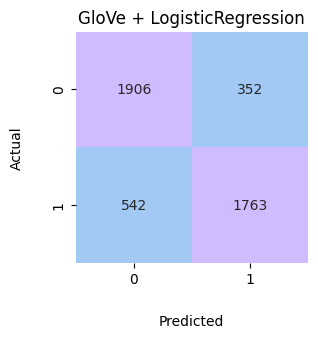

accuracy:	0.8040762656147271
precision:	0.8063653833125287
recall:		0.8040762656147271
f1:		0.803820346634661


In [569]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'GloVe + LogisticRegression')

#### 9.2 KNN

In [570]:
from sklearn.neighbors import KNeighborsClassifier


clf = KNeighborsClassifier(n_neighbors=3)
clf.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

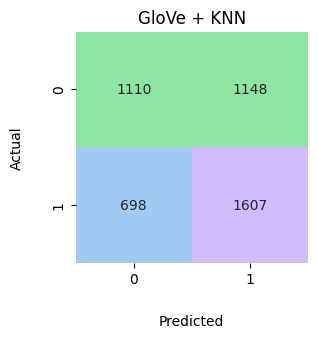

accuracy:	0.5954415954415955
precision:	0.5984627954216635
recall:		0.5954415954415955
f1:		0.5910438282067274


In [571]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'GloVe + KNN')

#### 9.3 SVC

In [572]:
clf = svm.SVC()
clf.fit(X_train, y_train)

SVC()

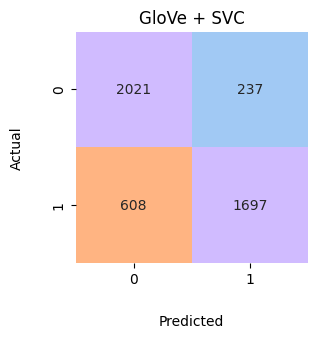

accuracy:	0.8148148148148148
precision:	0.8236546391280223
recall:		0.8148148148148148
f1:		0.8137402826888386


In [573]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'GloVe + SVC')

#### 9.4 GradientBoosting

In [574]:
clf = GradientBoostingClassifier(n_estimators=100, learning_rate=1.0, max_depth=1, random_state=RANDOM_STATE)
clf.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=1.0, max_depth=1, random_state=42)

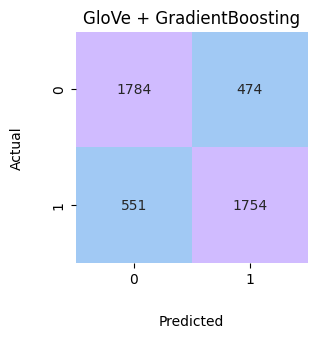

accuracy:	0.7753670830593907
precision:	0.7757590430274559
recall:		0.7753670830593907
f1:		0.7753421598932796


In [575]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'GloVe + GradientBoosting')

### Вывод

In [587]:
metrics_df = pd.DataFrame(metrics).T
cols = metrics_df.columns.tolist()
cols = cols[-1:] + cols[:-1]
metrics_df = metrics_df[cols].sort_values(by=['f1'], ascending=False)
metrics_df

,f1,accuracy,precision,recall
BoW + LogisticRegression,0.842618,0.843962,0.857899,0.843962
TF-IDF + GradientBoosting,0.820078,0.825115,0.869505,0.825115
GloVe + SVC,0.813740,0.814815,0.823655,0.814815
TF-IDF + LogisticRegression,0.813651,0.814815,0.824341,0.814815
GloVe + LogisticRegression,0.803820,0.804076,0.806365,0.804076
GloVe + GradientBoosting,0.775342,0.775367,0.775759,0.775367
BoW + SVC,0.774110,0.776463,0.790288,0.776463
TF-IDF + SVC,0.770434,0.773176,0.788816,0.773176
N-grams + Naive Byas,0.625644,0.627000,0.628141,0.627000
dict,0.596467,0.597633,0.599513,0.597633


Из baseline моделей наилучшие результаты показали GloVe + SVC, TF-IDF + GradientBoosting и BoW + LogisticRegression. Стоит отметить, что BoW + LogisticRegression один из самых быстрых методов и при этом находится среди лучших результатов.

